NEU-DET Grayscale CNN Baseline

This notebook trains a small CNN and compares learned image features with the classical ML baseline.

Setup and Data Loaders

The fixed train and validation folders are loaded as one-channel grayscale images.

In [2]:
from pathlib import Path
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
ROOT = PROJECT / 'dataset' / 'NEU-DET'
OUTPUTS = PROJECT / 'outputs' / 'neu_cnn'
OUTPUTS.mkdir(parents=True, exist_ok=True)
transform = transforms.Compose([transforms.Grayscale(num_output_channels=1), transforms.ToTensor(), transforms.Normalize((.5,), (.5,))])
train_data = datasets.ImageFolder(ROOT / 'train' / 'images', transform=transform)
validation_data = datasets.ImageFolder(ROOT / 'validation' / 'images', transform=transform)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=32, shuffle=False)
classes = train_data.classes
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(classes, device)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches'] cuda


CNN Model

Two convolution blocks learn local surface patterns before classification into six defect categories.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, class_count):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 50 * 50, 128), nn.ReLU(), nn.Dropout(.3), nn.Linear(128, class_count))
    def forward(self, x):
        return self.classifier(self.features(x))

model = SmallCNN(len(classes)).to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

Training

The training loop records loss and validation accuracy for each epoch.

In [4]:
history = []
for epoch in range(10):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_function(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in validation_loader:
            prediction = model(images.to(device)).argmax(1).cpu()
            correct += (prediction == labels).sum().item()
            total += len(labels)
    history.append({'epoch': epoch + 1, 'loss': total_loss / len(train_loader), 'validation_accuracy': correct / total})
    print(history[-1])
history = pd.DataFrame(history)

{'epoch': 1, 'loss': 1.3147808485560948, 'validation_accuracy': 0.5777777777777777}
{'epoch': 2, 'loss': 0.7857498632536994, 'validation_accuracy': 0.6}
{'epoch': 3, 'loss': 0.47990887860457104, 'validation_accuracy': 0.4638888888888889}
{'epoch': 4, 'loss': 0.44632105098830327, 'validation_accuracy': 0.7944444444444444}
{'epoch': 5, 'loss': 0.3161191678709454, 'validation_accuracy': 0.7583333333333333}
{'epoch': 6, 'loss': 0.29020789861679075, 'validation_accuracy': 0.8833333333333333}
{'epoch': 7, 'loss': 0.26871163414584265, 'validation_accuracy': 0.8861111111111111}
{'epoch': 8, 'loss': 0.21434107737408745, 'validation_accuracy': 0.7638888888888888}
{'epoch': 9, 'loss': 0.17676166428460016, 'validation_accuracy': 0.8611111111111112}
{'epoch': 10, 'loss': 0.17039780476027064, 'validation_accuracy': 0.8083333333333333}


Evaluation

Classification reports and confusion matrices show which defect types the CNN confuses.

                 precision    recall  f1-score   support

        crazing       0.97      0.60      0.74        60
      inclusion       0.72      0.60      0.65        60
        patches       0.71      0.97      0.82        60
 pitted_surface       0.74      0.90      0.81        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.81      0.78      0.80        60

       accuracy                           0.81       360
      macro avg       0.83      0.81      0.80       360
   weighted avg       0.83      0.81      0.80       360



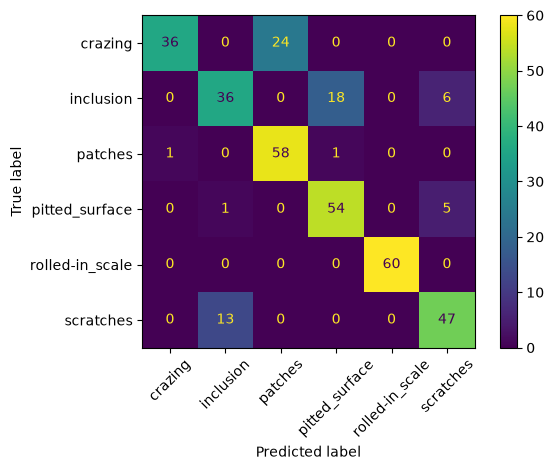

In [5]:
model.eval()
actual, predicted = [], []
with torch.no_grad():
    for images, labels in validation_loader:
        predicted.extend(model(images.to(device)).argmax(1).cpu().numpy())
        actual.extend(labels.numpy())
print(classification_report(actual, predicted, target_names=classes))
ConfusionMatrixDisplay.from_predictions(actual, predicted, display_labels=classes, xticks_rotation=45)
plt.tight_layout()
plt.savefig(OUTPUTS / 'cnn_confusion_matrix.png', bbox_inches='tight')
plt.show()
history.to_csv(OUTPUTS / 'cnn_training_history.csv', index=False)
torch.save(model.state_dict(), OUTPUTS / 'small_cnn.pt')

Findings

The CNN result will be compared with the Random Forest feature baseline before feature fusion is attempted.

In [6]:
print('The CNN learns spatial defect patterns directly from grayscale images.')
print('The comparison with Random Forest shows whether handcrafted analytics remain competitive.')
print('DCT and morphology will be added as an analytics-assisted input in the next notebook if useful.')

The CNN learns spatial defect patterns directly from grayscale images.
The comparison with Random Forest shows whether handcrafted analytics remain competitive.
DCT and morphology will be added as an analytics-assisted input in the next notebook if useful.
